# Phân tích kết quả Label Flipping

Notebook này trực quan hóa ba thí nghiệm theo hướng dẫn đồ án:

| Thí nghiệm | Nội dung | Điều kiện |
|---|---|---|
| E-LF1 | Random Label Flipping – quét poisoning rate | Sweep, subset 30%, 3 epochs, seed 42 |
| E-LF2 | Targeted Label Flipping | Sweep, subset 30%, 3 epochs, seed 42 |
| E-LF3 | Kiểm chứng các mốc đã chọn | Confirm, full train, 5 epochs, seeds 42/43/44 |

**Nguyên tắc so sánh**
- Sweep chỉ so với Baseline sweep; Confirm chỉ so với Baseline confirm cùng seed. Không so sánh chéo hai mode.
- Sweep chỉ có một seed nên không báo cáo độ lệch chuẩn.
- Điểm gãy theo D7: poisoning rate đầu tiên có Accuracy giảm **hơn 1 điểm phần trăm** so với Baseline cùng mode.
- Random và Targeted có mẫu số poisoning rate khác nhau. Khi so sánh, cần xem thêm tỷ lệ mẫu bị poison trên toàn bộ train set.

Notebook tập trung vào các đầu ra được yêu cầu tại mục 3.7: hiệu suất tổng thể, ảnh hưởng theo lớp, confusion matrix, so sánh Random/Targeted và kết quả confirm.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support
)

In [2]:
# Mount Google Drive và xác định thư mục kết quả
import sys

SHARED_FOLDER_NAME = "data-poisoning-shared"
DRIVE_MOUNT = Path("/content/drive")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT))

_candidates = [
    DRIVE_MOUNT / "MyDrive" / SHARED_FOLDER_NAME,
    DRIVE_MOUNT / "Shareddrives" / SHARED_FOLDER_NAME,
]
shared_drives = DRIVE_MOUNT / "Shareddrives"
if shared_drives.is_dir():
    _candidates.extend(sorted(shared_drives.glob(f"*/{SHARED_FOLDER_NAME}")))

DRIVE_ROOT = next((p for p in _candidates if p.is_dir()), None)
if DRIVE_ROOT is None:
    raise FileNotFoundError(
        f"Không tìm thấy {SHARED_FOLDER_NAME}. "
        "Hãy chỉnh DRIVE_ROOT thủ công nếu thư mục dùng chung có tên/vị trí khác."
    )

# Mặc định theo cấu trúc results dùng chung của dự án.
LF_RESULTS = DRIVE_ROOT / "results" / "label_flipping"
BASELINE_RESULTS = DRIVE_ROOT / "results" / "baseline"

# Nếu repo lưu kết quả ở vị trí khác, chỉnh hai biến trên.
# Ví dụ:
# LF_RESULTS = DRIVE_ROOT / "experiments" / "label_flipping" / "results"

if not LF_RESULTS.is_dir():
    raise FileNotFoundError(f"Không tìm thấy Label Flipping results: {LF_RESULTS}")
if not BASELINE_RESULTS.is_dir():
    raise FileNotFoundError(f"Không tìm thấy Baseline results: {BASELINE_RESULTS}")

print("Label Flipping:", LF_RESULTS)
print("Baseline      :", BASELINE_RESULTS)

Mounted at /content/drive
Label Flipping: /content/drive/MyDrive/data-poisoning-shared/results/label_flipping
Baseline      : /content/drive/MyDrive/data-poisoning-shared/results/baseline


## 1. Cấu hình và hàm đọc dữ liệu

Notebook đọc `metrics.json` và `predictions.csv` của từng run. Không chạy lại mô hình và không cần checkpoint.

Nếu kết quả E-LF2 không lưu source/target class trong `metrics.json`, có thể khai báo ID của hai lớp ở biến `SOURCE_CLASS_ID` và `TARGET_CLASS_ID` bên dưới để bật phân tích riêng cho cặp targeted.

In [3]:
NUM_CLASSES = 38
SWEEP_SEED = 42
CONFIRM_SEEDS = [42, 43, 44]
KNEE_THRESHOLD_PP = 1.0

# Chỉ điền nếu metrics.json không chứa thông tin source/target.
SOURCE_CLASS_ID = None
TARGET_CLASS_ID = None

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True
})

def read_predictions(path):
    # Hỗ trợ CSV hoặc TSV.
    with open(path, "r", encoding="utf-8") as f:
        header = f.readline()
    sep = "\t" if "\t" in header else ","
    df = pd.read_csv(path, sep=sep)
    required = {"sample_id", "y_true", "y_pred"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path}: thiếu cột {missing}")
    return df

def class_name_from_id(sample_id):
    # Ví dụ: test:Apple___Apple_scab/xxx.JPG
    return str(sample_id).split(":", 1)[-1].split("/")[0]

def metrics_from_predictions(pred):
    y_true, y_pred = pred["y_true"], pred["y_pred"]
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)),
        average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": p,
        "recall": r,
        "f1_score": f1
    }

def per_class_table(pred):
    p, r, f1, support = precision_recall_fscore_support(
        pred["y_true"], pred["y_pred"],
        labels=list(range(NUM_CLASSES)), zero_division=0
    )
    names = (
        pred.drop_duplicates("y_true")
        .set_index("y_true")["sample_id"]
        .map(class_name_from_id)
        .to_dict()
    )
    return pd.DataFrame({
        "class_id": range(NUM_CLASSES),
        "class_name": [names.get(i, str(i)) for i in range(NUM_CLASSES)],
        "precision": p,
        "recall": r,
        "f1_score": f1,
        "support": support
    })

def find_baseline_run(mode, seed):
    # Hỗ trợ baseline/sweep/seed_42, baseline/exploratory/seed_42
    # và các thư mục có tên mode nằm sâu hơn.
    candidates = [
        BASELINE_RESULTS / mode / f"seed_{seed}",
        BASELINE_RESULTS / "exploratory" / f"seed_{seed}" if mode == "sweep" else BASELINE_RESULTS / "confirm" / f"seed_{seed}"
    ]
    candidates.extend(
        p.parent for p in BASELINE_RESULTS.rglob("predictions.csv")
        if p.parent.name == f"seed_{seed}" and mode in p.parts
    )
    for folder in candidates:
        if (folder / "predictions.csv").is_file():
            pred = read_predictions(folder / "predictions.csv")
            return {"dir": folder, "pred": pred, "metrics": metrics_from_predictions(pred)}
    return None

In [4]:
# Đọc tất cả run thuộc E-LF1, E-LF2, E-LF3
records = []

for experiment in ["E-LF1", "E-LF2", "E-LF3"]:
    exp_dir = LF_RESULTS / experiment
    if not exp_dir.is_dir():
        print(f"[Thiếu thư mục] {experiment}")
        continue

    for metrics_path in sorted(exp_dir.rglob("metrics.json")):
        with open(metrics_path, "r", encoding="utf-8") as f:
            m = json.load(f)

        run_dir = metrics_path.parent
        pred_path = run_dir / "predictions.csv"
        if not pred_path.is_file():
            print(f"[Bỏ qua] Thiếu predictions.csv: {run_dir}")
            continue

        ev = m.get("evaluation", {})
        attack = m.get("attack", {}).get("flipped_label_adoption", {})
        records.append({
            "experiment": experiment,
            "run_dir": run_dir,
            "rate": float(m["poisoning_rate"]),
            "seed": int(m["run_seed"]),
            "strategy": m.get("strategy", "unknown"),
            "scope": m.get("dataset_scope", "unknown"),
            "train_samples": m.get("train_samples"),
            "test_samples": m.get("test_samples"),
            "epochs": m.get("epochs"),
            "accuracy": ev.get("accuracy"),
            "precision": ev.get("precision"),
            "recall": ev.get("recall"),
            "f1_score": ev.get("f1_score"),
            "num_flipped": attack.get("num_flipped_samples"),
            "adopted_count": attack.get("predicted_as_flipped_label_count"),
            "adoption_rate": attack.get("predicted_as_flipped_label_rate")
        })

runs = pd.DataFrame(records)
if runs.empty:
    raise RuntimeError("Không tìm thấy run hợp lệ trong E-LF1, E-LF2, E-LF3.")

runs["effective_rate"] = (
    runs["num_flipped"] / runs["train_samples"]
)
runs = runs.sort_values(["experiment", "rate", "seed"]).reset_index(drop=True)

print(f"Đã đọc {len(runs)} run.")
display(runs[[
    "experiment", "strategy", "rate", "seed", "scope",
    "accuracy", "precision", "recall", "f1_score"
]].round(4))

Đã đọc 19 run.


,experiment,strategy,rate,seed,scope,accuracy,precision,recall,f1_score
0,E-LF1,random,0.01,42,subset,0.9303,0.9050,0.9121,0.9015
1,E-LF1,random,0.02,42,subset,0.9265,0.9118,0.9035,0.8989
2,E-LF1,random,0.05,42,subset,0.9026,0.8904,0.8658,0.8624
3,E-LF1,random,0.10,42,subset,0.8882,0.8694,0.8436,0.8337
4,E-LF1,random,0.20,42,subset,0.8536,0.8394,0.7856,0.7893
5,E-LF1,random,0.30,42,subset,0.7836,0.7982,0.7228,0.7268
6,E-LF1,random,0.40,42,subset,0.7078,0.7462,0.6283,0.6196
7,E-LF2,targeted,0.05,42,subset,0.9327,0.9173,0.9112,0.9085
8,E-LF2,targeted,0.10,42,subset,0.9303,0.9132,0.9075,0.9045
9,E-LF2,targeted,0.20,42,subset,0.9237,0.9106,0.8994,0.8918


In [5]:
# Load predictions và Baseline tương ứng
PREDICTIONS = {
    row.run_dir: read_predictions(row.run_dir / "predictions.csv")
    for row in runs.itertuples()
}

BASELINE = {"sweep": {}, "confirm": {}}
BASELINE["sweep"][SWEEP_SEED] = find_baseline_run("sweep", SWEEP_SEED)

if BASELINE["sweep"][SWEEP_SEED] is None:
    raise FileNotFoundError(
        "Không tìm thấy Baseline sweep seed 42 có predictions.csv. "
        "Cần Baseline sweep để làm mốc 0% cho E-LF1/E-LF2."
    )

for seed in CONFIRM_SEEDS:
    BASELINE["confirm"][seed] = find_baseline_run("confirm", seed)

print("Baseline sweep:", BASELINE["sweep"][SWEEP_SEED]["dir"])
print("Baseline confirm có sẵn:", [
    s for s, item in BASELINE["confirm"].items() if item is not None
])

Baseline sweep: /content/drive/MyDrive/data-poisoning-shared/results/baseline/sweep/seed_42
Baseline confirm có sẵn: [42, 43, 44]


## 2. E-LF1 – Random Label Flipping

Đây là kết quả chính để trả lời RQ1. Đường Baseline là mốc 0% poisoning. Bảng thể hiện đầy đủ Accuracy, Precision, Recall và F1-score; biểu đồ tập trung vào Accuracy và macro-F1 theo yêu cầu hướng dẫn.

In [6]:
lf1 = runs[
    (runs["experiment"] == "E-LF1") &
    (runs["seed"] == SWEEP_SEED)
].sort_values("rate").copy()

if lf1.empty:
    raise RuntimeError("Không tìm thấy E-LF1 sweep seed 42.")

base_sweep = BASELINE["sweep"][SWEEP_SEED]["metrics"]
lf1["delta_accuracy_pp"] = (lf1["accuracy"] - base_sweep["accuracy"]) * 100
lf1["delta_f1_pp"] = (lf1["f1_score"] - base_sweep["f1_score"]) * 100

display(lf1[[
    "rate", "accuracy", "precision", "recall", "f1_score",
    "delta_accuracy_pp", "delta_f1_pp"
]].rename(columns={"rate": "poisoning_rate"}).round(4))

,poisoning_rate,accuracy,precision,recall,f1_score,delta_accuracy_pp,delta_f1_pp
0,0.01,0.9303,0.9050,0.9121,0.9015,-0.0552,-0.4366
1,0.02,0.9265,0.9118,0.9035,0.8989,-0.4321,-0.7036
2,0.05,0.9026,0.8904,0.8658,0.8624,-2.8227,-4.3500
3,0.10,0.8882,0.8694,0.8436,0.8337,-4.2663,-7.2169
4,0.20,0.8536,0.8394,0.7856,0.7893,-7.7234,-11.6552
5,0.30,0.7836,0.7982,0.7228,0.7268,-14.7297,-17.9075
6,0.40,0.7078,0.7462,0.6283,0.6196,-22.3060,-28.6297


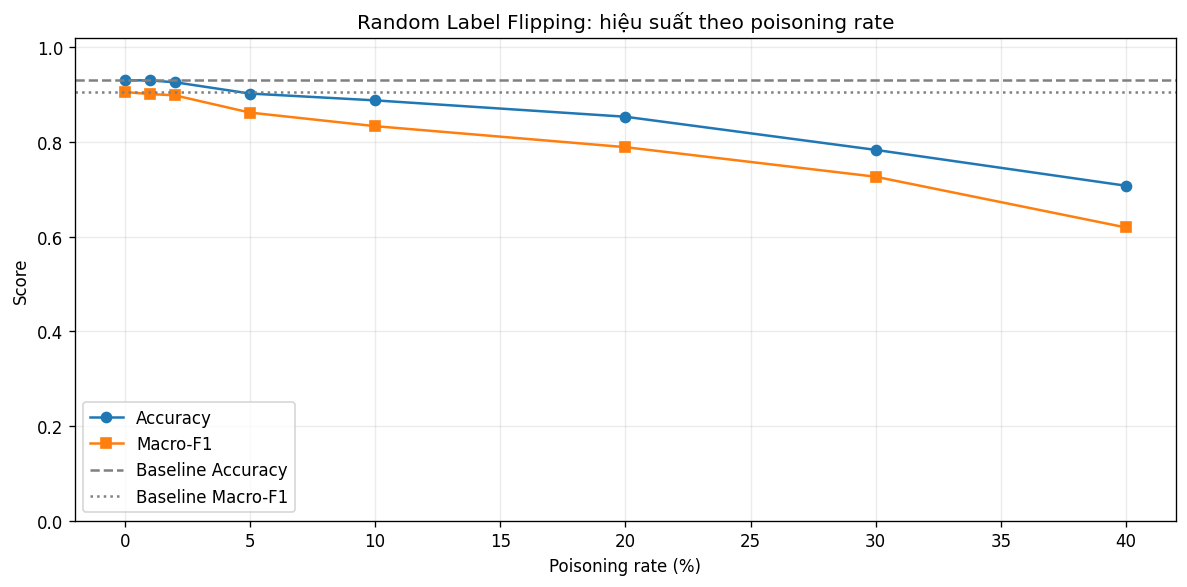

In [7]:
# Accuracy và macro-F1 theo poisoning rate, kèm Baseline 0%
curve = pd.DataFrame([{
    "rate": 0.0,
    "accuracy": base_sweep["accuracy"],
    "f1_score": base_sweep["f1_score"]
}])
curve = pd.concat([
    curve,
    lf1[["rate", "accuracy", "f1_score"]]
], ignore_index=True).sort_values("rate")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(curve["rate"] * 100, curve["accuracy"], marker="o", label="Accuracy")
ax.plot(curve["rate"] * 100, curve["f1_score"], marker="s", label="Macro-F1")
ax.axhline(base_sweep["accuracy"], linestyle="--", color="gray",
           label="Baseline Accuracy")
ax.axhline(base_sweep["f1_score"], linestyle=":", color="gray",
           label="Baseline Macro-F1")
ax.set(
    title="Random Label Flipping: hiệu suất theo poisoning rate",
    xlabel="Poisoning rate (%)",
    ylabel="Score"
)
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
# Xác định điểm gãy theo D7
knee_candidates = lf1[
    (base_sweep["accuracy"] - lf1["accuracy"]) * 100 > KNEE_THRESHOLD_PP
].sort_values("rate")

if knee_candidates.empty:
    print(
        f"Không ghi nhận điểm gãy theo D7 trong dải đã quét "
        f"(Accuracy chưa giảm quá {KNEE_THRESHOLD_PP} điểm % so với Baseline)."
    )
else:
    knee_rate = float(knee_candidates.iloc[0]["rate"])
    print(f"Điểm gãy theo D7: {knee_rate * 100:g}%")
    print("Nếu đường cong giảm mạnh giữa hai mốc, cân nhắc bổ sung một poisoning rate ở giữa.")

Điểm gãy theo D7: 5%
Nếu đường cong giảm mạnh giữa hai mốc, cân nhắc bổ sung một poisoning rate ở giữa.


## 3. Ảnh hưởng theo lớp – E-LF1

Theo hướng dẫn, sử dụng một trong hai cách: Heatmap F1 theo lớp và poisoning rate, hoặc biểu đồ 10 lớp giảm F1 nhiều nhất. Để dễ đọc và thuyết trình, notebook chọn biểu đồ Top 10.

In [9]:
# Top 10 lớp giảm F1 nhiều nhất tại poisoning rate cao nhất
high_run = lf1.sort_values("rate").iloc[-1]
high_pred = PREDICTIONS[high_run["run_dir"]]
base_pred = BASELINE["sweep"][SWEEP_SEED]["pred"]

base_pc = per_class_table(base_pred)
high_pc = per_class_table(high_pred)

class_compare = base_pc[["class_id", "class_name", "f1_score"]].merge(
    high_pc[["class_id", "f1_score"]],
    on="class_id", suffixes=("_baseline", "_poisoned")
)
class_compare["f1_drop"] = (
    class_compare["f1_score_baseline"] - class_compare["f1_score_poisoned"]
)
top10 = class_compare.sort_values("f1_drop", ascending=False).head(10)

display(top10[[
    "class_name", "f1_score_baseline",
    "f1_score_poisoned", "f1_drop"
]].round(4))

,class_name,f1_score_baseline,f1_score_poisoned,f1_drop
22,Potato___healthy,0.8182,0.0000,0.8182
2,Apple___Cedar_apple_rust,0.9204,0.2688,0.6515
20,Potato___Early_blight,0.9700,0.3673,0.6027
31,Tomato___Leaf_Mold,0.8608,0.2793,0.5815
27,Strawberry___healthy,0.9945,0.4237,0.5708
14,Grape___healthy,0.9882,0.4386,0.5496
21,Potato___Late_blight,0.8993,0.3765,0.5227
36,Tomato___Tomato_mosaic_virus,0.8806,0.3830,0.4976
5,Cherry_(including_sour)___Powdery_mildew,0.9659,0.4911,0.4748
8,Corn_(maize)___Common_rust_,0.9917,0.5515,0.4402


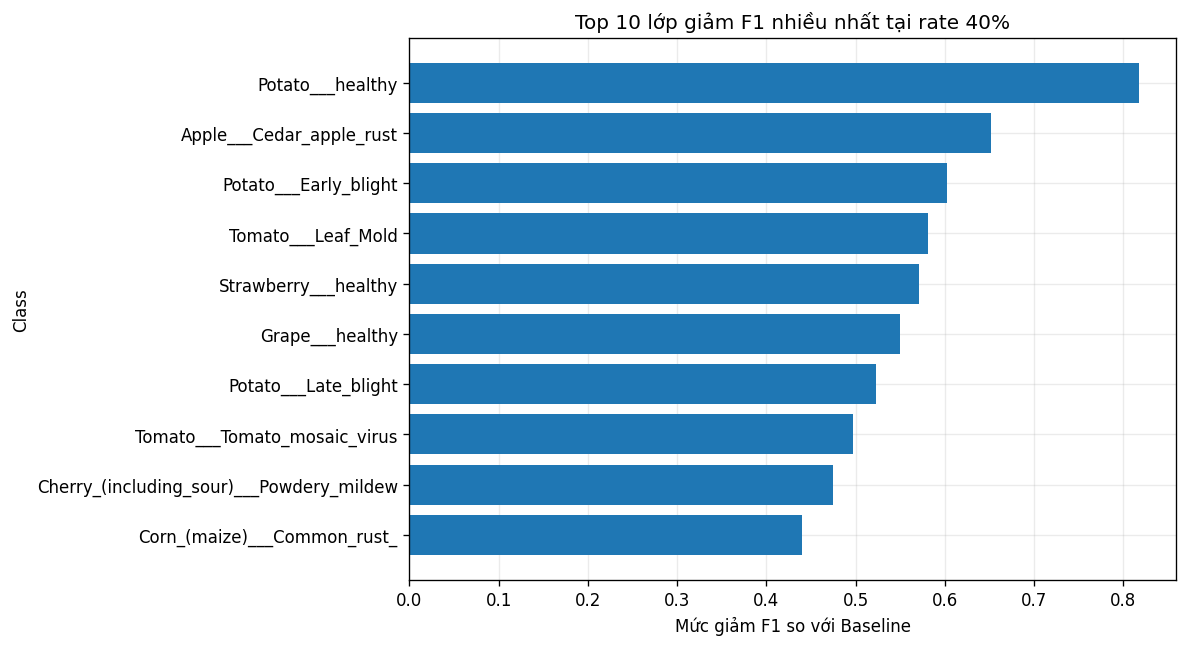

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df = top10.sort_values("f1_drop")
ax.barh(plot_df["class_name"], plot_df["f1_drop"])
ax.set(
    title=f"Top 10 lớp giảm F1 nhiều nhất tại rate {high_run['rate']*100:g}%",
    xlabel="Mức giảm F1 so với Baseline",
    ylabel="Class"
)
plt.tight_layout()
plt.show()

## 4. Confusion Matrix – Baseline và E-LF1 tại rate cao

So sánh hai confusion matrix chuẩn hóa theo hàng. Mục đích là quan sát các lớp bị phân loại nhầm sang lớp nào sau khi áp dụng Label Flipping. Hai ma trận được tính từ `predictions.csv`, không phụ thuộc ảnh confusion matrix được lưu sẵn.

/tmp/ipykernel_1669/541609628.py:23: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


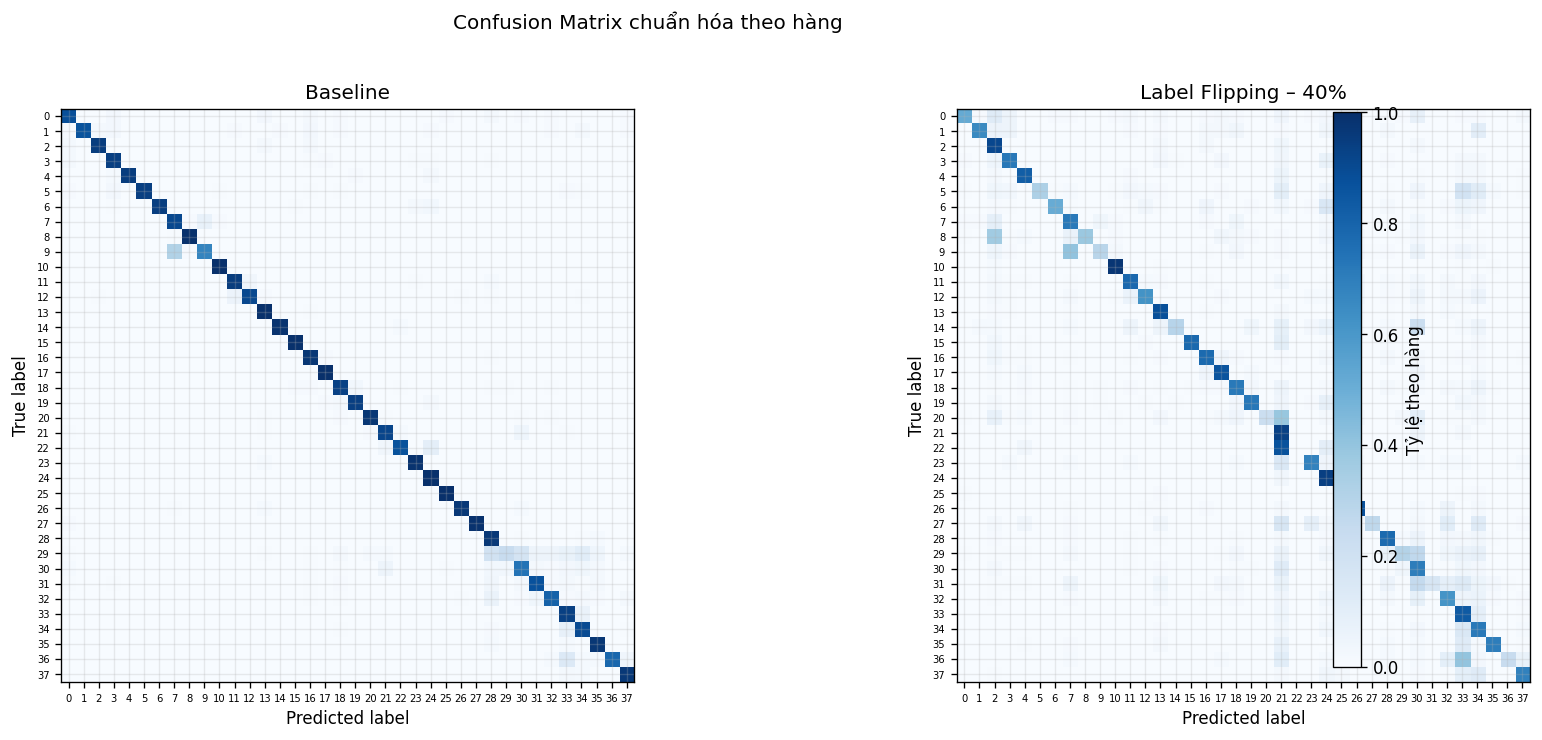

In [11]:
labels = list(range(NUM_CLASSES))
cm_base = confusion_matrix(
    base_pred["y_true"], base_pred["y_pred"], labels=labels, normalize="true"
)
cm_poison = confusion_matrix(
    high_pred["y_true"], high_pred["y_pred"], labels=labels, normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cm, title in [
    (axes[0], cm_base, "Baseline"),
    (axes[1], cm_poison, f"Label Flipping – {high_run['rate']*100:g}%")
]:
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(range(NUM_CLASSES))
    ax.set_yticks(range(NUM_CLASSES))
    ax.tick_params(axis="both", labelsize=6)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.025, label="Tỷ lệ theo hàng")
plt.suptitle("Confusion Matrix chuẩn hóa theo hàng", y=1.02)
plt.tight_layout()
plt.show()

## 5. E-LF2 – Targeted Label Flipping và so sánh chiến lược

Báo cáo kết quả Targeted theo poisoning rate và so sánh Random/Targeted tại các mức rate danh nghĩa chung. Cần đọc kèm `effective_rate` – số mẫu bị flip chia cho tổng số mẫu train – vì:
- Random: rate tính trên toàn bộ train set.
- Targeted: rate mặc định tính trên số mẫu thuộc source class.

Do đó, cùng rate danh nghĩa không đồng nghĩa với cùng số lượng mẫu bị poisoning.

In [12]:
lf2 = runs[
    (runs["experiment"] == "E-LF2") &
    (runs["seed"] == SWEEP_SEED)
].sort_values("rate").copy()

if lf2.empty:
    print("Không tìm thấy E-LF2 sweep seed 42.")
else:
    display(lf2[[
        "rate", "num_flipped", "train_samples", "effective_rate",
        "accuracy", "precision", "recall", "f1_score"
    ]].round(4))

    # So sánh các poisoning rate danh nghĩa xuất hiện ở cả E-LF1 và E-LF2.
    common_rates = sorted(set(lf1["rate"]) & set(lf2["rate"]))
    comparison = pd.concat([
        lf1[lf1["rate"].isin(common_rates)].assign(strategy_label="Random"),
        lf2[lf2["rate"].isin(common_rates)].assign(strategy_label="Targeted")
    ])
    display(comparison[[
        "strategy_label", "rate", "effective_rate",
        "accuracy", "f1_score"
    ]].sort_values(["rate", "strategy_label"]).round(4))

,rate,num_flipped,train_samples,effective_rate,accuracy,precision,recall,f1_score
7,0.05,12,13028,0.0009,0.9327,0.9173,0.9112,0.9085
8,0.10,24,13028,0.0018,0.9303,0.9132,0.9075,0.9045
9,0.20,47,13028,0.0036,0.9237,0.9106,0.8994,0.8918


,strategy_label,rate,effective_rate,accuracy,f1_score
2,Random,0.05,0.0500,0.9026,0.8624
7,Targeted,0.05,0.0009,0.9327,0.9085
3,Random,0.10,0.1000,0.8882,0.8337
8,Targeted,0.10,0.0018,0.9303,0.9045
4,Random,0.20,0.2000,0.8536,0.7893
9,Targeted,0.20,0.0036,0.9237,0.8918


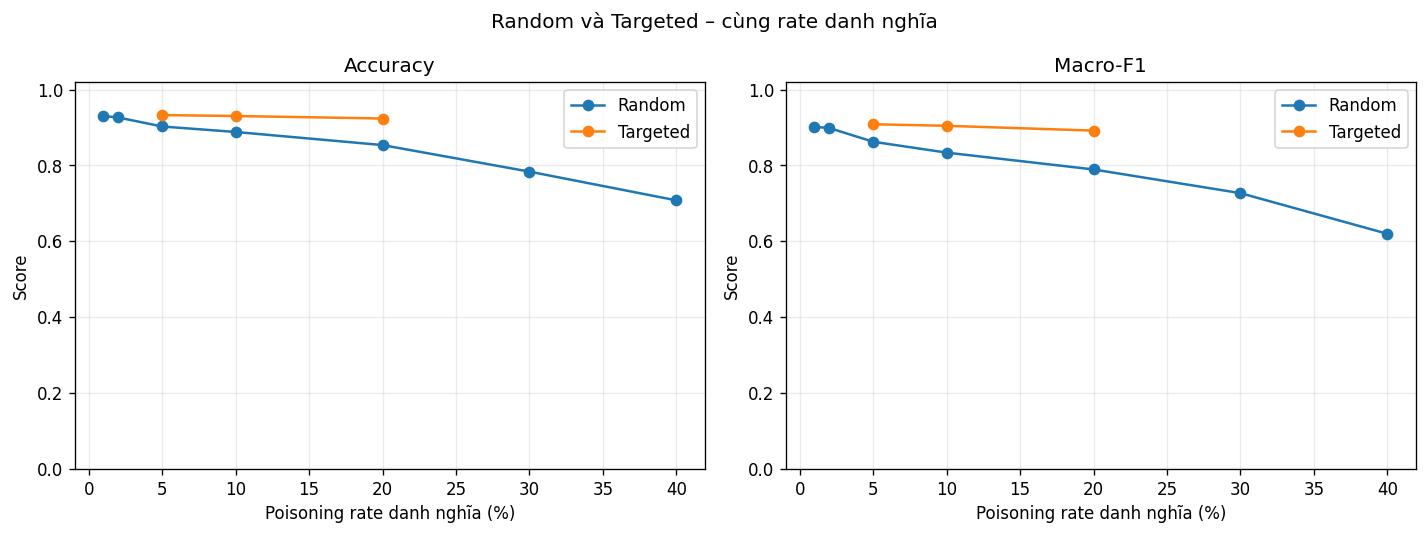

In [13]:
if not lf2.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for strategy_name, frame in [
        ("Random", lf1), ("Targeted", lf2)
    ]:
        axes[0].plot(frame["rate"] * 100, frame["accuracy"],
                     marker="o", label=strategy_name)
        axes[1].plot(frame["rate"] * 100, frame["f1_score"],
                     marker="o", label=strategy_name)

    axes[0].set_title("Accuracy")
    axes[1].set_title("Macro-F1")
    for ax in axes:
        ax.set_xlabel("Poisoning rate danh nghĩa (%)")
        ax.set_ylabel("Score")
        ax.set_ylim(0, 1.02)
        ax.legend()
    fig.suptitle("Random và Targeted – cùng rate danh nghĩa")
    plt.tight_layout()
    plt.show()

## 6. E-LF3 – Confirm trên full train

Chỉ so sánh E-LF3 với Baseline confirm cùng seed. Nếu Baseline confirm chưa có hoặc thiếu seed tương ứng, run đó không được đưa vào so sánh. Mean ± std được tính trên các seed có đủ cả hai phía; độ lệch chuẩn dùng `ddof=1`.

In [15]:
lf3 = runs[runs["experiment"] == "E-LF3"].copy()
confirm_records = []

for row in lf3.itertuples():
    base = BASELINE["confirm"].get(row.seed)
    if base is None:
        continue
    confirm_records.append({
        "rate": row.rate,
        "seed": row.seed,
        "accuracy": row.accuracy,
        "f1_score": row.f1_score,
        "baseline_accuracy": base["metrics"]["accuracy"],
        "baseline_f1": base["metrics"]["f1_score"]
    })

confirm_df = pd.DataFrame(confirm_records)

if confirm_df.empty:
    print(
        "Chưa thể phân tích E-LF3: không tìm thấy Baseline confirm "
        "cùng seed. Không so sánh E-LF3 với Baseline sweep."
    )
else:
    confirm_df["delta_accuracy_pp"] = (
        confirm_df["accuracy"] - confirm_df["baseline_accuracy"]
    ) * 100
    confirm_df["delta_f1_pp"] = (
        confirm_df["f1_score"] - confirm_df["baseline_f1"]
    ) * 100

    confirm_summary = confirm_df.groupby("rate").agg(
        n_seeds=("seed", "nunique"),
        accuracy_mean=("accuracy", "mean"),
        accuracy_std=("accuracy", "std"),
        f1_mean=("f1_score", "mean"),
        f1_std=("f1_score", "std"),
        delta_accuracy_mean_pp=("delta_accuracy_pp", "mean"),
        delta_f1_mean_pp=("delta_f1_pp", "mean")
    ).reset_index()

    display(confirm_summary.round(4))

,rate,n_seeds,accuracy_mean,accuracy_std,f1_mean,f1_std,delta_accuracy_mean_pp,delta_f1_mean_pp
0,0.05,3,0.9216,0.0074,0.9003,0.0100,-2.9606,-3.6610
1,0.10,3,0.9111,0.0019,0.8841,0.0047,-4.0150,-5.2741
2,0.20,3,0.8692,0.0015,0.8343,0.0020,-8.2046,-10.2568


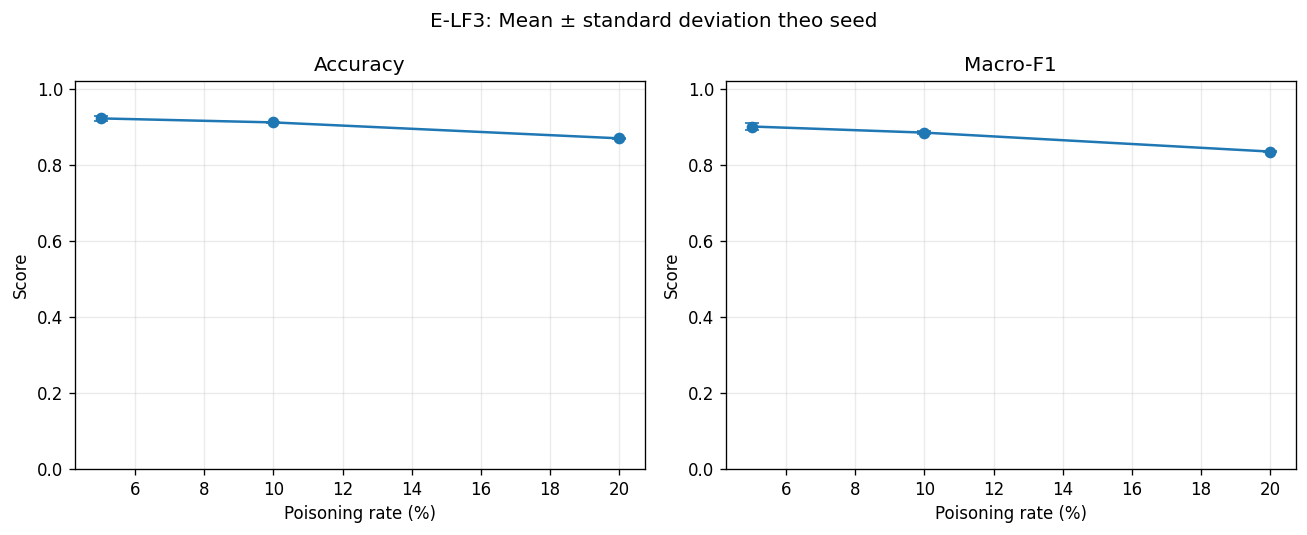

In [16]:
if not confirm_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, mean_col, std_col, title in [
        (axes[0], "accuracy_mean", "accuracy_std", "Accuracy"),
        (axes[1], "f1_mean", "f1_std", "Macro-F1")
    ]:
        ax.errorbar(
            confirm_summary["rate"] * 100,
            confirm_summary[mean_col],
            yerr=confirm_summary[std_col].fillna(0),
            marker="o", capsize=4
        )
        ax.set_title(title)
        ax.set_xlabel("Poisoning rate (%)")
        ax.set_ylabel("Score")
        ax.set_ylim(0, 1.02)
    fig.suptitle("E-LF3: Mean ± standard deviation theo seed")
    plt.tight_layout()
    plt.show()

## 7. Metric phụ: Flipped-label adoption (nếu pipeline cung cấp)

Đây là metric tùy chọn trong hướng dẫn. Notebook chỉ trình bày số lượng và tỷ lệ được ghi trong `metrics.json`; không diễn giải adoption rate như một ASR hoặc bằng chứng độc lập rằng mô hình đã ghi nhớ nhãn nhiễu.

In [17]:
adoption_df = runs[
    (runs["experiment"].isin(["E-LF1", "E-LF2"])) &
    runs["adoption_rate"].notna()
][[
    "experiment", "rate", "seed", "num_flipped",
    "adopted_count", "adoption_rate"
]].sort_values(["experiment", "rate"])

if adoption_df.empty:
    print("metrics.json không cung cấp flipped_label_adoption.")
else:
    display(adoption_df.round(4))

,experiment,rate,seed,num_flipped,adopted_count,adoption_rate
0,E-LF1,0.01,42,130,2,0.0154
1,E-LF1,0.02,42,261,4,0.0153
2,E-LF1,0.05,42,651,9,0.0138
3,E-LF1,0.10,42,1303,23,0.0177
4,E-LF1,0.20,42,2606,60,0.0230
5,E-LF1,0.30,42,3908,89,0.0228
6,E-LF1,0.40,42,5211,137,0.0263
7,E-LF2,0.05,42,12,9,0.7500
8,E-LF2,0.10,42,24,13,0.5417
9,E-LF2,0.20,42,47,39,0.8298


## 8. Xuất bảng kết quả

Lưu các bảng tổng hợp vào `results/label_flipping/analysis/`. Không ghi đè các file kết quả gốc của từng run.

In [18]:
ANALYSIS_DIR = LF_RESULTS / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

runs_export = runs.drop(columns=["run_dir"], errors="ignore")
runs_export.to_csv(ANALYSIS_DIR / "label_flipping_runs_summary.csv", index=False)

if not lf1.empty:
    lf1.drop(columns=["run_dir"], errors="ignore").to_csv(
        ANALYSIS_DIR / "E-LF1_summary.csv", index=False
    )

if not lf2.empty:
    lf2.drop(columns=["run_dir"], errors="ignore").to_csv(
        ANALYSIS_DIR / "E-LF2_summary.csv", index=False
    )

if not confirm_df.empty:
    confirm_df.to_csv(ANALYSIS_DIR / "E-LF3_confirm_comparison.csv", index=False)
    confirm_summary.to_csv(ANALYSIS_DIR / "E-LF3_confirm_mean_std.csv", index=False)

if "top10" in globals():
    top10.to_csv(ANALYSIS_DIR / "E-LF1_top10_class_f1_drop.csv", index=False)

print("Đã xuất bảng phân tích tại:", ANALYSIS_DIR)

Đã xuất bảng phân tích tại: /content/drive/MyDrive/data-poisoning-shared/results/label_flipping/analysis


## 9. Checklist kết luận

Sau khi xem kết quả, hoàn thiện các ý sau trong báo cáo:

1. **RQ1 – Random Label Flipping:** Accuracy và macro-F1 thay đổi thế nào khi poisoning rate tăng? Có điểm gãy theo D7 hay không?
2. **Ảnh hưởng theo lớp:** Những lớp nào giảm F1 nhiều nhất tại mốc rate cao? Confusion matrix cho thấy chúng thường bị nhầm sang lớp nào?
3. **Targeted Label Flipping:** Source class có giảm recall và bị dự đoán thành target class hay không? Nêu rõ mẫu số poisoning rate khi so sánh với Random.
4. **Confirm:** Các kết quả trên full train có nhất quán với xu hướng sweep không? Chỉ kết luận dựa trên Baseline confirm cùng seed.
5. **Giới hạn:** Sweep chỉ có một seed. Nếu Accuracy/F1 ít suy giảm, đó vẫn là kết quả hợp lệ; cần ghi nhận giới hạn cấu hình và phạm vi thực nghiệm, không suy diễn rằng attack không có tác động trong mọi điều kiện.

**Bàn giao cho Defense:** giữ checkpoint và poison manifest của các run được chọn để dùng ở giai đoạn phòng thủ.